# IDS — Two-stage detection

## Load libraries and set up the experiment.

In [1]:
from pathlib import Path
import re, json, hashlib, gc, platform
import numpy as np
import pandas as pd
import joblib
import matplotlib.pyplot as plt
from PIL import Image
from tqdm.auto import tqdm
from scipy import ndimage as ndi
from scipy.spatial import cKDTree
from scipy.signal import fftconvolve
from skimage.color import rgb2hed, rgb2hsv, rgb2gray
from skimage.measure import label, regionprops
from skimage.filters import threshold_otsu, sobel, gabor_kernel
from skimage.feature import local_binary_pattern
from sklearn.preprocessing import StandardScaler, normalize
from sklearn.covariance import LedoitWolf
from sklearn.neighbors import NearestNeighbors
from sklearn.metrics import (roc_auc_score, average_precision_score, roc_curve,
    precision_recall_curve, confusion_matrix, accuracy_score, precision_score,
    recall_score, f1_score, balanced_accuracy_score)
import torch
from torchvision import models

SEED = 17
np.random.seed(SEED)
torch.manual_seed(SEED)
DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'
ROOT = Path('/kaggle/input')
OUT = Path('/kaggle/working/IDS_results')
for folder in ['tables', 'figures']:
    (OUT / folder).mkdir(parents=True, exist_ok=True)

SIZE = 256
MIN_TISSUE = .50
BATCH = 16
KNN_K = 5
BOOTSTRAPS = 400

## Read SICAPv2 labels and split the slides.

In [2]:
roots=[]
for p in ROOT.rglob('Train.xlsx'):
    if p.parent.name.lower()=='test' and p.parent.parent.name.lower()=='partition':
        candidate=p.parent.parent.parent
        if (candidate/'images').is_dir() and (candidate/'partition/Test/Test.xlsx').is_file():roots.append(candidate)
DATA=sorted(roots,key=lambda x:(len(str(x)),str(x)))[0]
files=sorted(p for p in (DATA/'images').rglob('*') if p.suffix.lower() in {'.jpg','.jpeg','.png','.tif','.tiff'})
stems=[p.stem.lower() for p in files]
fileid=hashlib.sha256(('\n'.join(stems)+'|'+str(SIZE)+'|'+str(MIN_TISSUE)).encode()).hexdigest()[:16]
labels=[]
for fn in (DATA/'partition/Test/Train.xlsx',DATA/'partition/Test/Test.xlsx'):
    t=pd.read_excel(fn);t.columns=[str(x).strip().upper() for x in t.columns]
    for col in ('NC','G3','G4','G4C','G5'):
        if col not in t:t[col]=0
        t[col]=pd.to_numeric(t[col],errors='coerce').fillna(0)
    t['grade']=np.select([t.G5.gt(0), t.G4.gt(0)|t.G4C.gt(0),t.G3.gt(0),t.NC.gt(0)],['G5','G4','G3','NC'],default='')
    t=t[t.grade.ne('')].copy()
    t['stem']=t.IMAGE_NAME.astype(str).map(lambda v:Path(v).stem.lower())
    t['partition']=fn.stem.lower()
    labels.append(t[['stem','grade','partition']])
lab=pd.concat(labels,ignore_index=True)
d=pd.DataFrame({'path':list(map(str,files)),'stem':stems}).merge(lab,on='stem',how='inner',validate='one_to_one').reset_index(drop=True)
d['slide']=d.stem.str.split('_block_region',n=1).str[0]
coords=d.stem.str.extract(r'_xini_(?P<x>\d+)_yini_(?P<y>\d+)',flags=re.I)
d['x']=pd.to_numeric(coords.x,errors='coerce');d['y']=pd.to_numeric(coords.y,errors='coerce')
known=['NC','G3','G4'];g5slides=set(d.loc[d.grade.eq('G5'),'slide'])
official=set(d.loc[d.partition.eq('test'),'slide'])
eligible=np.array(sorted(set(d.loc[d.grade.isin(known)&d.partition.eq('train'),'slide'])-g5slides-official),object)
train_cut=max(1,int(len(eligible)*.60));val_cut=max(train_cut+1,int(len(eligible)*.80))
best=None;coverage_best=-1
for attempt in tqdm(range(100),desc='Slide-disjoint split selection'):
    perm=np.random.RandomState(SEED+attempt).permutation(eligible)
    split=(set(perm[:train_cut]),set(perm[train_cut:val_cut]),set(perm[val_cut:]))
    counts=[d.loc[d.partition.eq('train')&d.slide.isin(s),'grade'].value_counts() for s in split]
    coverage=sum(min(int(ct.get(c,0)),5) for ct in counts for c in known)
    if coverage>coverage_best:best=split;coverage_best=coverage
    if all(ct.get(c,0)>=5 for ct in counts for c in known):best=split;break
train_slides,val_slides,cal_slides=best
role=np.full(len(d),'unassigned',dtype=object)
for name,sl in [('train',train_slides),('val',val_slides),('cal',cal_slides)]:
    role[d.grade.isin(known).to_numpy()&d.slide.isin(sl).to_numpy()]=name
is_official=d.partition.eq('test').to_numpy()
known_te=is_official&d.grade.isin(known).to_numpy()
g5_te=is_official&d.grade.eq('G5').to_numpy()
role[known_te]='test';role[g5_te]='unk'
d['role']=role
print('Full image count',len(files),'Labelled rows',len(d),'roles',d.role.value_counts().to_dict())

Slide-disjoint split selection:   0%|          | 0/100 [00:00<?, ?it/s]

Full image count 18783 Labelled rows 12081 roles {'train': 4741, 'unassigned': 2083, 'test': 1890, 'val': 1775, 'cal': 1360, 'unk': 232}


## Extract nuclear, architecture and texture features.

In [3]:
KERNELS=[gabor_kernel(fr,theta=t*np.pi/4) for fr in (.1,.2,.4) for t in range(4)]
NUC=['count','area_mean','area_std','nuclear_fraction','eccentricity','solidity','nn_mean','nn_std']
ARC=['lumen_fraction','lumen_count','mean_lumen_area','stroma_fraction','edge_density']
TEX=[f'gabor{i}_{j}' for i in range(12) for j in ('mean','std')]+[f'lbp{i}' for i in range(10)]
def load_img(path,side=SIZE):
    with Image.open(path) as im:return np.asarray(im.convert('RGB').resize((side,side)),dtype=np.float32)/255.
def morph_one(path):
    img=load_img(path);tissue=float((rgb2hsv(img)[...,1]>.1).mean())
    if tissue<MIN_TISSUE:return tissue,None
    h=ndi.gaussian_filter(rgb2hed(img)[...,0],1)
    mask=ndi.binary_opening(h>threshold_otsu(h))
    props=[p for p in regionprops(label(mask)) if p.area>=20]
    if len(props)<2:nu=np.full(8,np.nan)
    else:
        ar=np.array([p.area for p in props]);cent=np.array([p.centroid for p in props]);nn=cKDTree(cent).query(cent,k=2)[0][:,1]
        nu=np.array([len(ar),ar.mean(),ar.std(),mask.mean(),np.mean([p.eccentricity for p in props]),np.mean([p.solidity for p in props]),nn.mean(),nn.std()])
    gray=rgb2gray(img);g=gray[::2,::2];g=(g-g.mean())/(g.std()+1e-6)
    tx=[]
    for kernel in KERNELS:
        response=np.abs(fftconvolve(g,kernel,mode='same'));tx.extend([response.mean(),response.std()])
    lbp=local_binary_pattern((gray*255).astype(np.uint8),8,1,'uniform').astype(int)
    tx=np.r_[tx,np.bincount(lbp.ravel(),minlength=10)[:10]/lbp.size]
    lum=ndi.binary_opening((rgb2hsv(img)[...,1]<.1)&(gray>.8),iterations=2)
    areas=[p.area for p in regionprops(label(lum)) if p.area>=50]
    e=ndi.gaussian_filter(rgb2hed(img)[...,1],1)
    ac=np.array([lum.mean(),len(areas),np.mean(areas) if areas else 0,(e>threshold_otsu(e)).mean(),sobel(gray).mean()])
    return tissue,(nu,tx,ac)

tissue = np.full(len(d), np.nan)
NU = np.full((len(d), 8), np.nan)
TX = np.full((len(d), 34), np.nan)
AC = np.full((len(d), 5), np.nan)

for i in tqdm(range(len(d)), desc='Extracting tissue features'):
    tissue[i], features = morph_one(d.path.iloc[i])
    if features is not None:
        NU[i], TX[i], AC[i] = features

d['tissue'] = tissue
d['valid'] = tissue >= MIN_TISSUE
d.to_csv(OUT/'tables'/'metadata_all.csv', index=False)
print('Usable patches:', d.valid.sum())

Extracting tissue features:   0%|          | 0/12081 [00:00<?, ?it/s]

Usable patches: 7655


## Compute Stage 1 scores and select suspicious slides.

In [4]:
tr=(d.role.eq('train')&d.valid).to_numpy();ca=(d.role.eq('cal')&d.valid).to_numpy()
va=(d.role.eq('val')&d.valid).to_numpy();test=(d.role.isin(['test','unk'])&d.valid).to_numpy()
G=d.grade.to_numpy();N=len(d)
def fit_maha(X,name,log_transform=False):
    X=X.copy().astype(float);missing=~np.isfinite(X)
    median=np.nanmedian(X[tr],axis=0);median=np.nan_to_num(median,nan=0)
    X=np.where(missing,median[None,:],X)
    if log_transform:X=np.log1p(np.maximum(X,0))
    scaler=StandardScaler().fit(X[tr]);z=scaler.transform(X)
    models={g:LedoitWolf().fit(z[tr&(G==g)]) for g in known}
    dist=np.min(np.stack([np.sqrt(np.maximum(0,models[g].mahalanobis(z))) for g in known]),axis=0)
    scale=max(np.quantile(dist[ca],.99),1e-8)
    return dist/scale
h={}
for name,X,logt in tqdm([('nuclear',NU,True),('architecture',AC,True),('texture',TX,False)],desc='Fitting Stage 1 experts'):
    if name=='texture':X=np.log1p(np.maximum(X,0))
    h[name]=fit_maha(X,name,logt)
raw=np.maximum(h['nuclear'],h['architecture'])
valid_frame=d[d.valid].copy();valid_frame['raw']=raw[d.valid.to_numpy()]
slide_means=valid_frame.groupby('slide')['raw'].mean()
d['stage1_score']=d.slide.map(slide_means).astype(float)
threshold=float(np.quantile(d.loc[ca].stage1_score,.90))
d['stage1_pass']=d.stage1_score>threshold
slide_table=d.loc[test].groupby('slide').agg(n=('stem','size'),g5=('grade',lambda s:int((s=='G5').sum())),stage1_score=('stage1_score','mean'),pass_stage1=('stage1_pass','first')).reset_index()
slide_table['label']=(slide_table.g5>0).astype(int)
slide_table['eligible']=(slide_table.g5.eq(0))|(slide_table.g5.ge(5))
slide_table.to_csv(OUT/'tables'/'stage1_slide_predictions.csv',index=False)
print('Stage1 threshold:',threshold,'test slides:',len(slide_table))

Fitting Stage 1 experts:   0%|          | 0/3 [00:00<?, ?it/s]

Stage1 threshold: 0.6783871316603167 test slides: 31


## Extract ResNet18 and Phikon image embeddings.

In [5]:
def batch_indices(indices, batch_size):
    for start in range(0, len(indices), batch_size):
        yield indices[start:start + batch_size]

def run_embed(name, dim, fn, batch_size):
    output = np.zeros((N, dim), dtype=np.float32)
    indices = np.flatnonzero(d.valid.to_numpy())
    batches = list(batch_indices(indices, batch_size))
    for ids in tqdm(batches, desc=name):
        images = []
        for j in ids:
            with Image.open(d.path.iloc[j]) as im:
                images.append(im.convert('RGB').copy())
        output[ids] = fn(images)
    return output

net = models.resnet18(weights=models.ResNet18_Weights.DEFAULT)
net.fc = torch.nn.Identity()
net = net.to(DEVICE).eval()
transform = models.ResNet18_Weights.DEFAULT.transforms()

def resnet_batch(images):
    x = torch.stack([transform(im) for im in images]).to(DEVICE)
    with torch.inference_mode():
        return net(x).float().cpu().numpy()

R = run_embed('ResNet18 embeddings', 512, resnet_batch, 32)
del net
gc.collect()
if DEVICE == 'cuda':
    torch.cuda.empty_cache()

from transformers import AutoImageProcessor, AutoModel
processor = AutoImageProcessor.from_pretrained('owkin/phikon')
vit = AutoModel.from_pretrained('owkin/phikon').to(DEVICE).eval()

def phikon_batch(images):
    batch = processor(images=images, return_tensors='pt')
    batch = {k: v.to(DEVICE) for k, v in batch.items()}
    with torch.inference_mode():
        return vit(**batch).last_hidden_state[:, 0, :].float().cpu().numpy()

P = run_embed('Phikon embeddings', int(vit.config.hidden_size), phikon_batch, 8)
del vit, processor
gc.collect()
if DEVICE == 'cuda':
    torch.cuda.empty_cache()
print('Embedding shapes:', P.shape, R.shape)

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 172MB/s] 


ResNet18 embeddings:   0%|          | 0/240 [00:00<?, ?it/s]

preprocessor_config.json:   0%|          | 0.00/171 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/492 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  346MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/200 [00:00<?, ?it/s]

Phikon embeddings:   0%|          | 0/957 [00:00<?, ?it/s]

Embedding shapes: (12081, 768) (12081, 512)


## Compute Stage 2 kNN scores and calibration thresholds.

In [6]:
FEATURES={'Phikon':np.asarray(P),'ResNet18':np.asarray(R),'Texture':np.log1p(np.maximum(np.nan_to_num(TX,nan=0),0))}
score_bank={}
def class_knn_scores(X, name):
    X=np.asarray(X,np.float32);sc=StandardScaler().fit(X[tr]);z=sc.transform(X)
    z=normalize(z)
    output=np.full(N,np.inf)
    banks={}
    for grade in tqdm(known,desc=f'{name} grade banks',leave=False):
        idx=np.flatnonzero(tr&(G==grade))
        if len(idx)>2000:idx=np.sort(np.random.default_rng(SEED+sum(map(ord,grade))).choice(idx,2000,replace=False))
        knn=NearestNeighbors(n_neighbors=min(KNN_K,len(idx)),metric='cosine',algorithm='brute').fit(z[idx])
        banks[grade]=knn
        for chunk in tqdm(list(batch_indices(np.flatnonzero(d.valid.to_numpy()),512)),desc=f'{name}/{grade} query',leave=False):
            distances=knn.kneighbors(z[chunk],return_distance=True)[0].mean(1)
            output[chunk]=np.minimum(output[chunk],distances)
    scale=max(float(np.quantile(output[ca],.95)),1e-8)
    return output/scale
for name, X in tqdm(FEATURES.items(), desc='Stage 2'):
    score_bank[name] = class_knn_scores(X, name)
score_bank['MoE_equal_mean']=np.mean([score_bank[z] for z in ('Phikon','ResNet18','Texture')],axis=0)
for name,score in score_bank.items():d[f's2_{name}']=score
thresholds={k:float(np.quantile(v[ca],.90)) for k,v in score_bank.items()}
print('Stage2 known-cal 90th percentile thresholds:',thresholds)

Stage 2:   0%|          | 0/3 [00:00<?, ?it/s]

Phikon grade banks:   0%|          | 0/3 [00:00<?, ?it/s]

Phikon/NC query:   0%|          | 0/15 [00:00<?, ?it/s]

Phikon/G3 query:   0%|          | 0/15 [00:00<?, ?it/s]

Phikon/G4 query:   0%|          | 0/15 [00:00<?, ?it/s]

ResNet18 grade banks:   0%|          | 0/3 [00:00<?, ?it/s]

... (4 outputs left out)

Texture/NC query:   0%|          | 0/15 [00:00<?, ?it/s]

Texture/G3 query:   0%|          | 0/15 [00:00<?, ?it/s]

Texture/G4 query:   0%|          | 0/15 [00:00<?, ?it/s]

Stage2 known-cal 90th percentile thresholds: {'Phikon': 0.9454245877067903, 'ResNet18': 0.9740654732723183, 'Texture': 0.852006950094119, 'MoE_equal_mean': 0.8431868328239776}


## Calculate the evaluation results.

In [7]:
from sklearn.metrics import matthews_corrcoef
idx=np.flatnonzero(test);y=(G[idx]=='G5').astype(int)

def evaluate(y,score,pred):
    y=np.asarray(y,int);score=np.asarray(score,float);pred=np.asarray(pred,int)
    tn,fp,fn,tp=confusion_matrix(y,pred,labels=[0,1]).ravel()
    return dict(n=len(y),positives=int(y.sum()),AUROC=float(roc_auc_score(y,score)),AUPRC=float(average_precision_score(y,score)),
                accuracy=float(accuracy_score(y,pred)),balanced_accuracy=float(balanced_accuracy_score(y,pred)),
                precision=float(precision_score(y,pred,zero_division=0)),recall=float(recall_score(y,pred,zero_division=0)),
                specificity=float(tn/(tn+fp)) if tn+fp else np.nan,F1=float(f1_score(y,pred,zero_division=0)),
                MCC=float(matthews_corrcoef(y,pred)),TN=int(tn),FP=int(fp),FN=int(fn),TP=int(tp))

rows=[]
for name in tqdm(score_bank,desc='Stage 2 evaluation'):
    s=score_bank[name][idx]; pred=s>thresholds[name]
    for scope,ix in [('ungated',np.ones(len(idx),bool)),('selected_slides',d.stage1_pass.to_numpy()[idx])]:
        if len(np.unique(y[ix]))<2:continue
        rows.append(dict(method=name,scope=scope,**evaluate(y[ix],s[ix],pred[ix])))
    gate=d.stage1_pass.to_numpy()[idx]
    adjusted=np.where(gate,s,np.nanmin(s)-1.)
    preds=gate&pred
    rows.append(dict(method=name,scope='end_to_end',**evaluate(y,adjusted,preds)))
metrics_df=pd.DataFrame(rows);metrics_df.to_csv(OUT/'tables'/'stage2_and_end_to_end_metrics.csv',index=False)
st=slide_table[(slide_table.g5>=5)|((slide_table.g5==0)&(slide_table.n>=5))].copy()
slide_metrics=evaluate(st.label,st.stage1_score,st.pass_stage1)
(OUT/'tables'/'stage1_metrics.json').write_text(json.dumps(slide_metrics,indent=2))
within=[]
for name in tqdm(score_bank,desc='Within-mixed-slide evaluation'):
    pairs=[]
    for slide,g in d.loc[test].groupby('slide'):
        yi=(g.grade=='G5').to_numpy().astype(int)
        if yi.sum()>=2 and (1-yi).sum()>=2:
            au=roc_auc_score(yi,g[f's2_{name}'].to_numpy())
            pairs.append((slide,au,int(yi.sum()*(1-yi).sum())))
    for slide,auc,weight in pairs:within.append({'method':name,'slide':slide,'within_slide_AUROC':auc,'weight':weight})
within_df=pd.DataFrame(within);within_df.to_csv(OUT/'tables'/'within_slide_AUROC.csv',index=False)
print('Stage1 eligible-slide metrics:',slide_metrics)
print(metrics_df[['method','scope','AUROC','AUPRC','precision','recall','F1','TP','FP']].round(4).to_string(index=False))
print('Within-slide AUROC (weighted):',within_df.groupby('method').apply(lambda g:np.average(g.within_slide_AUROC,weights=g.weight)).round(4).to_dict() if len(within_df) else 'N/A')
cols=['stem','path','slide','x','y','grade','role','valid','tissue','stage1_score','stage1_pass']+[f's2_{name}' for name in score_bank]
d[cols].to_csv(OUT/'tables'/'all_predictions.csv',index=False)
(OUT/'run_settings.json').write_text(json.dumps({'dataset_signature':fileid,'seed':SEED,'device':DEVICE,'python':platform.python_version(),'torch':torch.__version__,'stage1_gate':threshold,'stage2_thresholds':thresholds,'Stage2_experts':['Phikon','ResNet18','Texture'],'fusion':'fixed equal mean','model_selection':'predeclared; no G5 used to tune','stage1_method':'per-slide mean of max nuclear/architecture class-conditional LedoitWolf distances','eligible_slide_exclusions':'1–4 G5 mixed slides excluded for slide AUROC only'},indent=2))

Stage 2 evaluation:   0%|          | 0/4 [00:00<?, ?it/s]

Within-mixed-slide evaluation:   0%|          | 0/4 [00:00<?, ?it/s]

Stage1 eligible-slide metrics: {'n': 29, 'positives': 5, 'AUROC': 0.9833333333333333, 'AUPRC': 0.9428571428571428, 'accuracy': 0.896551724137931, 'balanced_accuracy': 0.8583333333333334, 'precision': 0.6666666666666666, 'recall': 0.8, 'specificity': 0.9166666666666666, 'F1': 0.7272727272727273, 'MCC': 0.6682951125722248, 'TN': 22, 'FP': 2, 'FN': 1, 'TP': 4}
        method           scope  AUROC  AUPRC  precision  recall     F1  TP  FP
        Phikon         ungated 0.5451 0.1379     0.1200  0.1508 0.1337  27 198
        Phikon selected_slides 0.4021 0.4011     0.2766  0.1538 0.1977  26  68
        Phikon      end_to_end 0.8816 0.3858     0.2766  0.1453 0.1905  26  68
      ResNet18         ungated 0.4137 0.1162     0.1041  0.1285 0.1150  23 198
      ResNet18 selected_slides 0.4340 0.4600     0.4259  0.1361 0.2063  23  31
      ResNet18      end_to_end 0.8862 0.4415     0.4259  0.1285 0.1974  23  31
       Texture         ungated 0.4566 0.1149     0.0748  0.0447 0.0559   8  99
       T

/tmp/ipykernel_49/4221313063.py:39: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  print('Within-slide AUROC (weighted):',within_df.groupby('method').apply(lambda g:np.average(g.within_slide_AUROC,weights=g.weight)).round(4).to_dict() if len(within_df) else 'N/A')


693

## Save the performance plots.

In [8]:
figdir=OUT/'figures'
for name in tqdm(score_bank,desc='Generating ROC/PR and confusion figures'):
    s=d.loc[test,f's2_{name}'].to_numpy();t=thresholds[name]
    fig,ax=plt.subplots(1,3,figsize=(14,4))
    fpr,tpr,_=roc_curve(y,s);ax[0].plot(fpr,tpr,label=f'AUROC {roc_auc_score(y,s):.3f}');ax[0].plot([0,1],[0,1],'--',color='gray');ax[0].legend();ax[0].set_title('ROC');ax[0].set_xlabel('FPR');ax[0].set_ylabel('TPR')
    pr,re,_=precision_recall_curve(y,s);ax[1].plot(re,pr,label=f'AP {average_precision_score(y,s):.3f}');ax[1].legend();ax[1].set_title('Precision–recall');ax[1].set_xlabel('Recall');ax[1].set_ylabel('Precision')
    cm=confusion_matrix(y,s>t,labels=[0,1]);ax[2].imshow(cm,cmap='Blues');ax[2].set_xticks([0,1],['Known','G5']);ax[2].set_yticks([0,1],['Known','G5']);ax[2].set_xlabel('Predicted');ax[2].set_ylabel('Actual');ax[2].set_title('Ungated confusion matrix')
    for a in range(2):
        for b in range(2):ax[2].text(b,a,int(cm[a,b]),ha='center',va='center')
    fig.suptitle(name);fig.tight_layout();fig.savefig(figdir/f'{name}_curves_cm.png',dpi=160);plt.close(fig)

fig,ax=plt.subplots(1,2,figsize=(10,4))
ax[0].plot(*roc_curve(st.label,st.stage1_score)[:2],lw=2);ax[0].plot([0,1],[0,1],'--',color='gray');ax[0].set_title('Stage 1 eligible-slide ROC');ax[0].set_xlabel('False positive rate');ax[0].set_ylabel('True positive rate')
scm=confusion_matrix(st.label,st.pass_stage1,labels=[0,1]);ax[1].imshow(scm,cmap='Blues');ax[1].set_title('Stage 1 confusion matrix');ax[1].set_xticks([0,1],['Known','Suspicious']);ax[1].set_yticks([0,1],['Known','Suspicious'])
for a in range(2):
    for b in range(2):ax[1].text(b,a,int(scm[a,b]),ha='center',va='center')
fig.tight_layout();fig.savefig(figdir/'stage1_eligible_slide_evaluation.png',dpi=160);plt.close(fig)

rng=np.random.default_rng(SEED);test_df=d.loc[test].copy();groups=[g for _,g in test_df.groupby('slide')]
boots=[]
for method in tqdm(score_bank,desc='Slide bootstrap confidence intervals'):
    vals=[]
    for _ in tqdm(range(BOOTSTRAPS),desc=method,leave=False):
        drawn=rng.integers(0,len(groups),size=len(groups));sample=pd.concat([groups[i] for i in drawn],ignore_index=True)
        yy=sample.grade.eq('G5').to_numpy().astype(int)
        if len(np.unique(yy))==2:vals.append(roc_auc_score(yy,sample[f's2_{method}'].to_numpy()))
    boots.append({'method':method,'metric':'ungated_patch_AUROC','CI_low':float(np.quantile(vals,.025)) if vals else np.nan,'CI_high':float(np.quantile(vals,.975)) if vals else np.nan,'bootstrap_valid':len(vals)})
pd.DataFrame(boots).to_csv(OUT/'tables'/'slide_bootstrap_CIs.csv',index=False)

fig,ax=plt.subplots(figsize=(13,3));ax.axis('off')
blocks=['SICAPv2 patches','Stage 1: nuclear + architecture\nMahalanobis','Slide mean gate','Stage 2: Phikon | ResNet18 | Texture\nclass-aware kNN','Equal-mean fusion\npatch predictions']
for k,txt in enumerate(blocks):
    x=k*.198
    ax.text(x+.085,.5,txt,ha='center',va='center',fontsize=9,bbox=dict(boxstyle='square,pad=.5',facecolor='white',edgecolor='black'),transform=ax.transAxes)
    if k<4:ax.annotate('',xy=(x+.185,.5),xytext=(x+.155,.5),xycoords=ax.transAxes,arrowprops={'arrowstyle':'->'})
fig.tight_layout();fig.savefig(figdir/'system_architecture.png',dpi=180);plt.close(fig)
print('Wrote curves, confusion matrices, bootstrap intervals and system diagram')

Generating ROC/PR and confusion figures:   0%|          | 0/4 [00:00<?, ?it/s]

Slide bootstrap confidence intervals:   0%|          | 0/4 [00:00<?, ?it/s]

Phikon:   0%|          | 0/400 [00:00<?, ?it/s]

ResNet18:   0%|          | 0/400 [00:00<?, ?it/s]

Texture:   0%|          | 0/400 [00:00<?, ?it/s]

MoE_equal_mean:   0%|          | 0/400 [00:00<?, ?it/s]

Wrote curves, confusion matrices, bootstrap intervals and system diagram


## Create a patch-level slide visualization.

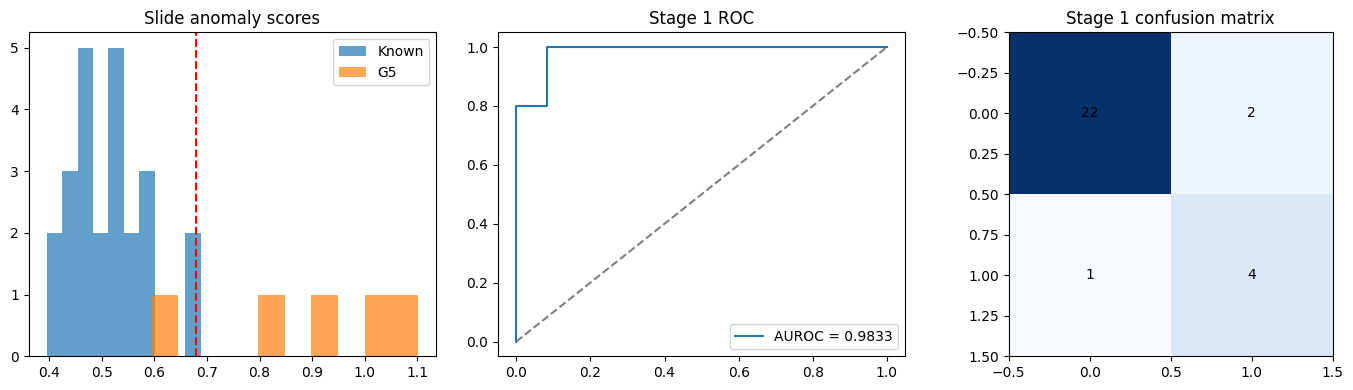

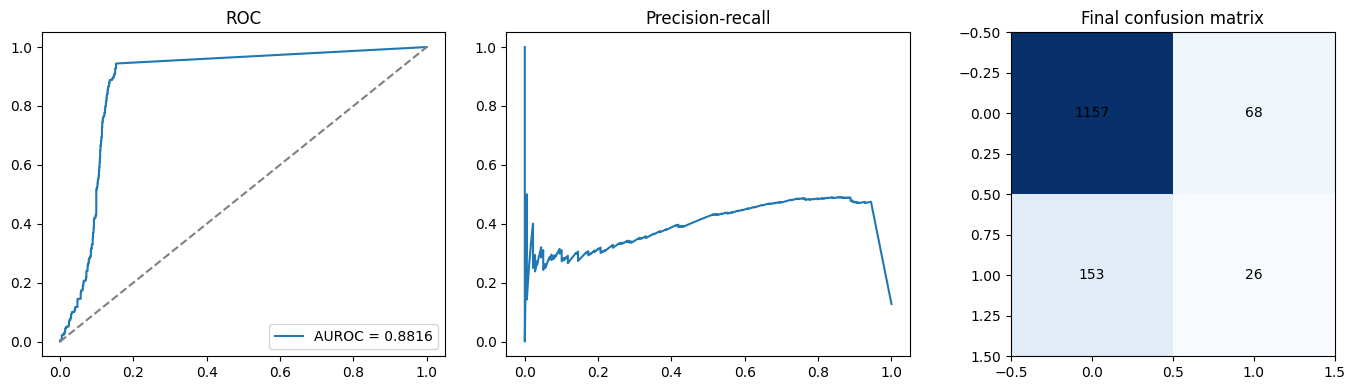

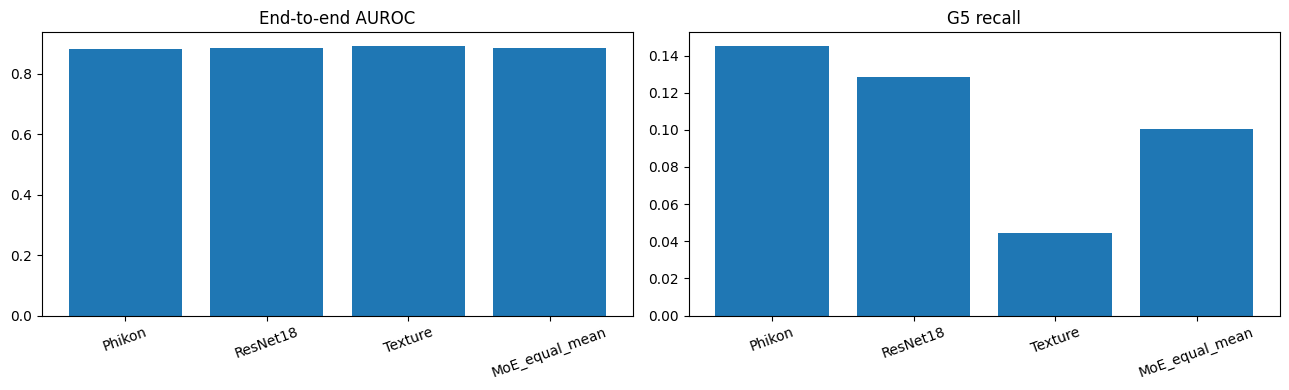

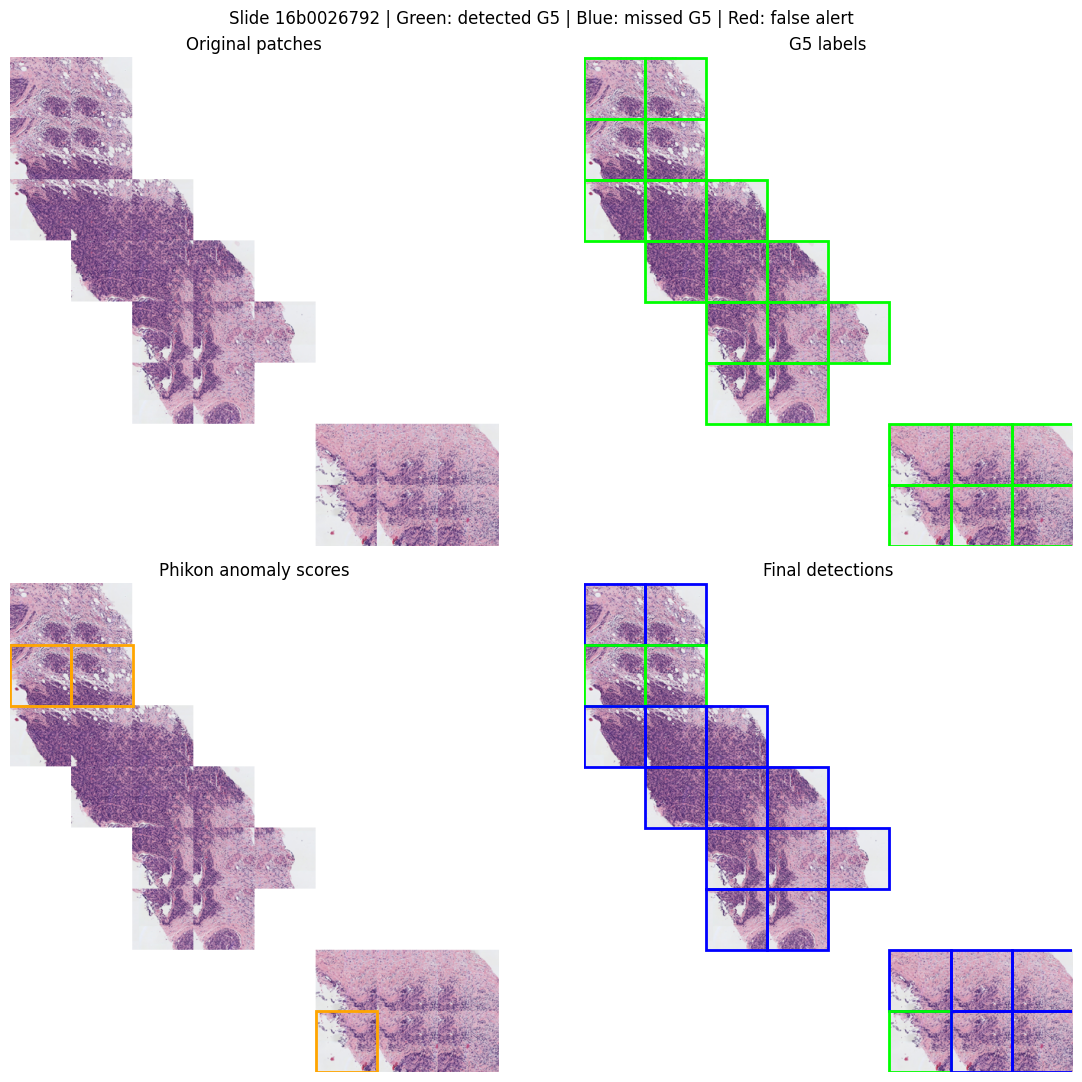

All figures saved in: /kaggle/working/IDS_results/figures


In [10]:

from pathlib import Path
from PIL import Image
import matplotlib.pyplot as plt
import numpy as np

folder = OUT / "figures"
folder.mkdir(parents=True, exist_ok=True)

def save(name):
    plt.tight_layout()
    plt.savefig(folder / f"{name}.png", dpi=160)
    plt.show()
    plt.close()

# Stage 1 evaluation
fig, ax = plt.subplots(1, 3, figsize=(14, 4))
ax[0].hist(st.loc[st.label == 0, 'stage1_score'], alpha=.7, label='Known')
ax[0].hist(st.loc[st.label == 1, 'stage1_score'], alpha=.7, label='G5')
ax[0].axvline(threshold, color='red', linestyle='--')
ax[0].set_title('Slide anomaly scores')
ax[0].legend()

fpr, tpr, _ = roc_curve(st.label, st.stage1_score)
ax[1].plot(fpr, tpr, label=f'AUROC = {roc_auc_score(st.label, st.stage1_score):.4f}')
ax[1].plot([0, 1], [0, 1], '--', color='gray')
ax[1].set_title('Stage 1 ROC')
ax[1].legend()

cm = confusion_matrix(st.label, st.pass_stage1)
ax[2].imshow(cm, cmap='Blues')
ax[2].set_title('Stage 1 confusion matrix')
for i in range(2):
    for j in range(2):
        ax[2].text(j, i, cm[i, j], ha='center', va='center')
save('stage1_evaluation')

# Final Stage 1 + Phikon evaluation
s = score_bank['Phikon'][test]
gate = d.loc[test, 'stage1_pass'].to_numpy()
scores = np.where(gate, s, s.min() - 1)
pred = gate & (s > thresholds['Phikon'])

fig, ax = plt.subplots(1, 3, figsize=(14, 4))
fpr, tpr, _ = roc_curve(y, scores)
ax[0].plot(fpr, tpr, label=f'AUROC = {roc_auc_score(y, scores):.4f}')
ax[0].plot([0, 1], [0, 1], '--', color='gray')
ax[0].set_title('ROC')
ax[0].legend()

precision, recall, _ = precision_recall_curve(y, scores)
ax[1].plot(recall, precision)
ax[1].set_title('Precision-recall')

cm = confusion_matrix(y, pred)
ax[2].imshow(cm, cmap='Blues')
ax[2].set_title('Final confusion matrix')
for i in range(2):
    for j in range(2):
        ax[2].text(j, i, cm[i, j], ha='center', va='center')
save('stage1_phikon_evaluation')

# Expert comparison
methods = list(score_bank)
aucs = []
recalls = []

for name in methods:
    scores = score_bank[name][test]
    decision = gate & (scores > thresholds[name])
    final_scores = np.where(gate, scores, scores.min() - 1)
    aucs.append(roc_auc_score(y, final_scores))
    recalls.append(recall_score(y, decision))

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
ax[0].bar(methods, aucs)
ax[0].set_title('End-to-end AUROC')
ax[1].bar(methods, recalls)
ax[1].set_title('G5 recall')
for a in ax:
    a.tick_params(axis='x', rotation=20)
save('expert_comparison')

# Slide patch map
slide = '16b0026792'
if slide not in set(d.slide):
    slide = d.loc[test & (d.grade == 'G5'), 'slide'].value_counts().index[0]

q = d[(d.slide == slide) & d.valid & d.role.isin(['test', 'unk'])].copy()
xs = sorted(q.x.dropna().unique())
ys = sorted(q.y.dropna().unique())
xs, ys = xs[:8], ys[:8]
q = q[q.x.isin(xs) & q.y.isin(ys)]

size = 80
canvas = np.full((len(ys)*size, len(xs)*size, 3), 255, dtype=np.uint8)

for r in q.itertuples():
    x, yy = xs.index(r.x)*size, ys.index(r.y)*size
    with Image.open(r.path) as im:
        canvas[yy:yy+size, x:x+size] = np.array(
            im.convert('RGB').resize((size, size))
        )

fig, ax = plt.subplots(2, 2, figsize=(12, 11))
titles = ['Original patches', 'G5 labels', 'Phikon anomaly scores', 'Final detections']

for a, title in zip(ax.flat, titles):
    a.imshow(canvas)
    a.set_title(title)
    a.axis('off')

for r in q.itertuples():
    x, yy = xs.index(r.x)*size, ys.index(r.y)*size
    actual = r.grade == 'G5'
    detected = r.stage1_pass and r.s2_Phikon > thresholds['Phikon']

    if actual:
        ax[0, 1].add_patch(plt.Rectangle((x, yy), size, size,
                           fill=False, edgecolor='lime', linewidth=2))

    if r.s2_Phikon > thresholds['Phikon']:
        ax[1, 0].add_patch(plt.Rectangle((x, yy), size, size,
                           fill=False, edgecolor='orange', linewidth=2))

    if actual or detected:
        color = 'lime' if actual and detected else 'blue' if actual else 'red'
        ax[1, 1].add_patch(plt.Rectangle((x, yy), size, size,
                           fill=False, edgecolor=color, linewidth=2))

fig.suptitle(f'Slide {slide} | Green: detected G5 | Blue: missed G5 | Red: false alert')
save('slide_patch_map')

print('All figures saved in:', folder)


In [12]:

# Stage 2 methods compared during experimentation
comparison = pd.DataFrame({
    'Method': ['Phikon kNN', 'ResNet18 kNN', 'Texture kNN',
               'Equal-weight fusion', 'Adaptive router'],
    'Within-slide AUROC': [0.7961, 0.5317, 0.4672, 0.5666, 0.6544],
    'End-to-end AUROC': [0.8816, 0.8862, 0.8923, 0.8844, 0.8782],
    'G5 detected (out of 179)': [26, 23, 8, 18, 23]
})

print("Stage 2 comparison (recorded full-experiment results)")
display(comparison)

print("\nPhikon was selected for the final Stage 2 model because")
print("it achieved the highest within-slide AUROC and detected")
print("the most G5 patches at the evaluated thresholds.")


Stage 2 comparison (recorded full-experiment results)


,Method,Within-slide AUROC,End-to-end AUROC,G5 detected (out of 179)
0,Phikon kNN,0.7961,0.8816,26
1,ResNet18 kNN,0.5317,0.8862,23
2,Texture kNN,0.4672,0.8923,8
3,Equal-weight fusion,0.5666,0.8844,18
4,Adaptive router,0.6544,0.8782,23



Phikon was selected for the final Stage 2 model because
it achieved the highest within-slide AUROC and detected
the most G5 patches at the evaluated thresholds.
